In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("smartcart_customers.csv")

In [3]:
df.shape

(2240, 22)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 22 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [5]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0


In [6]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
Complain                0
Response                0
dtype: int64

## Data Preprocessing

In [7]:
# Handle missing values 

df["Income"] = df["Income"].fillna(df["Income"].median())

In [8]:
df.isnull().sum()

ID                     0
Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Kidhome                0
Teenhome               0
Dt_Customer            0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
Complain               0
Response               0
dtype: int64

## Feature Engineering

In [9]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response'],
      dtype='object')

In [10]:
# Year_Birth -> Age
df["Age"] = 2026 - df["Year_Birth"] 

In [11]:
# Dt_Customer -> Customer_Tenure_Days
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], dayfirst = True)

reference_date = df["Dt_Customer"].max()
df["Customer_Tenure_Days"] = (reference_date - df["Dt_Customer"]).dt.days

In [12]:
# Total_Spending
df["Total_Spending"] = df["MntWines"] + df["MntFruits"] + df["MntMeatProducts"] + df["MntFishProducts"] + df["MntFishProducts"] + df["MntSweetProducts"] + df["MntGoldProds"]

In [13]:
# Total_Children
df["Total_Children"] = df["Kidhome"] + df["Teenhome"]

In [14]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,8,10,4,7,0,1,69,663,1789,0
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,1,1,2,5,0,0,72,113,29,2
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,8,2,10,4,0,0,61,312,887,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,2,0,4,6,0,0,42,139,63,1
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,5,3,6,5,0,0,45,161,468,1


In [18]:
# Education
df["Education"].value_counts()

Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64

In [19]:
# Education - Undergraduate, Graduate, Postgraduate
df["Education"] = df["Education"].replace({
    "Basic" : "Undergraduate", "2n Cycle" : "Undergraduate",
    "Graduation" : "Graduate",
    "Master" : "Postgraduate", "PhD" : "Postgraduate"
})

In [20]:
df["Education"].value_counts()

Education
Graduate         1127
Postgraduate      856
Undergraduate     257
Name: count, dtype: int64

In [21]:
# Marital Status
df["Marital_Status"].value_counts()

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64

In [25]:
df["Living_With"] = df["Marital_Status"].replace({
    "Married" : "Partner", "Together" : "Partner",
    "Single" : "Alone", "Divorced" : "Alone", "Widow" : "Alone", 
    "Absurd" : "Alone", "YOLO" : "Alone"
})

In [26]:
df["Living_With"].value_counts()

Living_With
Partner    1444
Alone       796
Name: count, dtype: int64

## Drop Columns

In [27]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response', 'Age', 'Customer_Tenure_Days', 'Total_Spending',
       'Total_Children', 'Living_With'],
      dtype='object')

In [28]:
cols = ["ID", "Year_Birth", "Marital_Status", "Kidhome", "Teenhome", "Dt_Customer"]
spending_cols = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]

cols_to_drop = cols + spending_cols

df_cleaned = df.drop(columns = cols_to_drop)

In [29]:
df_cleaned.shape

(2240, 15)

In [30]:
df_cleaned.columns

Index(['Education', 'Income', 'Recency', 'NumDealsPurchases',
       'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases',
       'NumWebVisitsMonth', 'Complain', 'Response', 'Age',
       'Customer_Tenure_Days', 'Total_Spending', 'Total_Children',
       'Living_With'],
      dtype='object')

In [31]:
df_cleaned.head()

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Living_With
0,Graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1789,0,Alone
1,Graduate,46344.0,38,2,1,1,2,5,0,0,72,113,29,2,Alone
2,Graduate,71613.0,26,1,8,2,10,4,0,0,61,312,887,0,Partner
3,Graduate,26646.0,26,2,2,0,4,6,0,0,42,139,63,1,Partner
4,Postgraduate,58293.0,94,5,5,3,6,5,0,0,45,161,468,1,Partner


## Handling Outliers

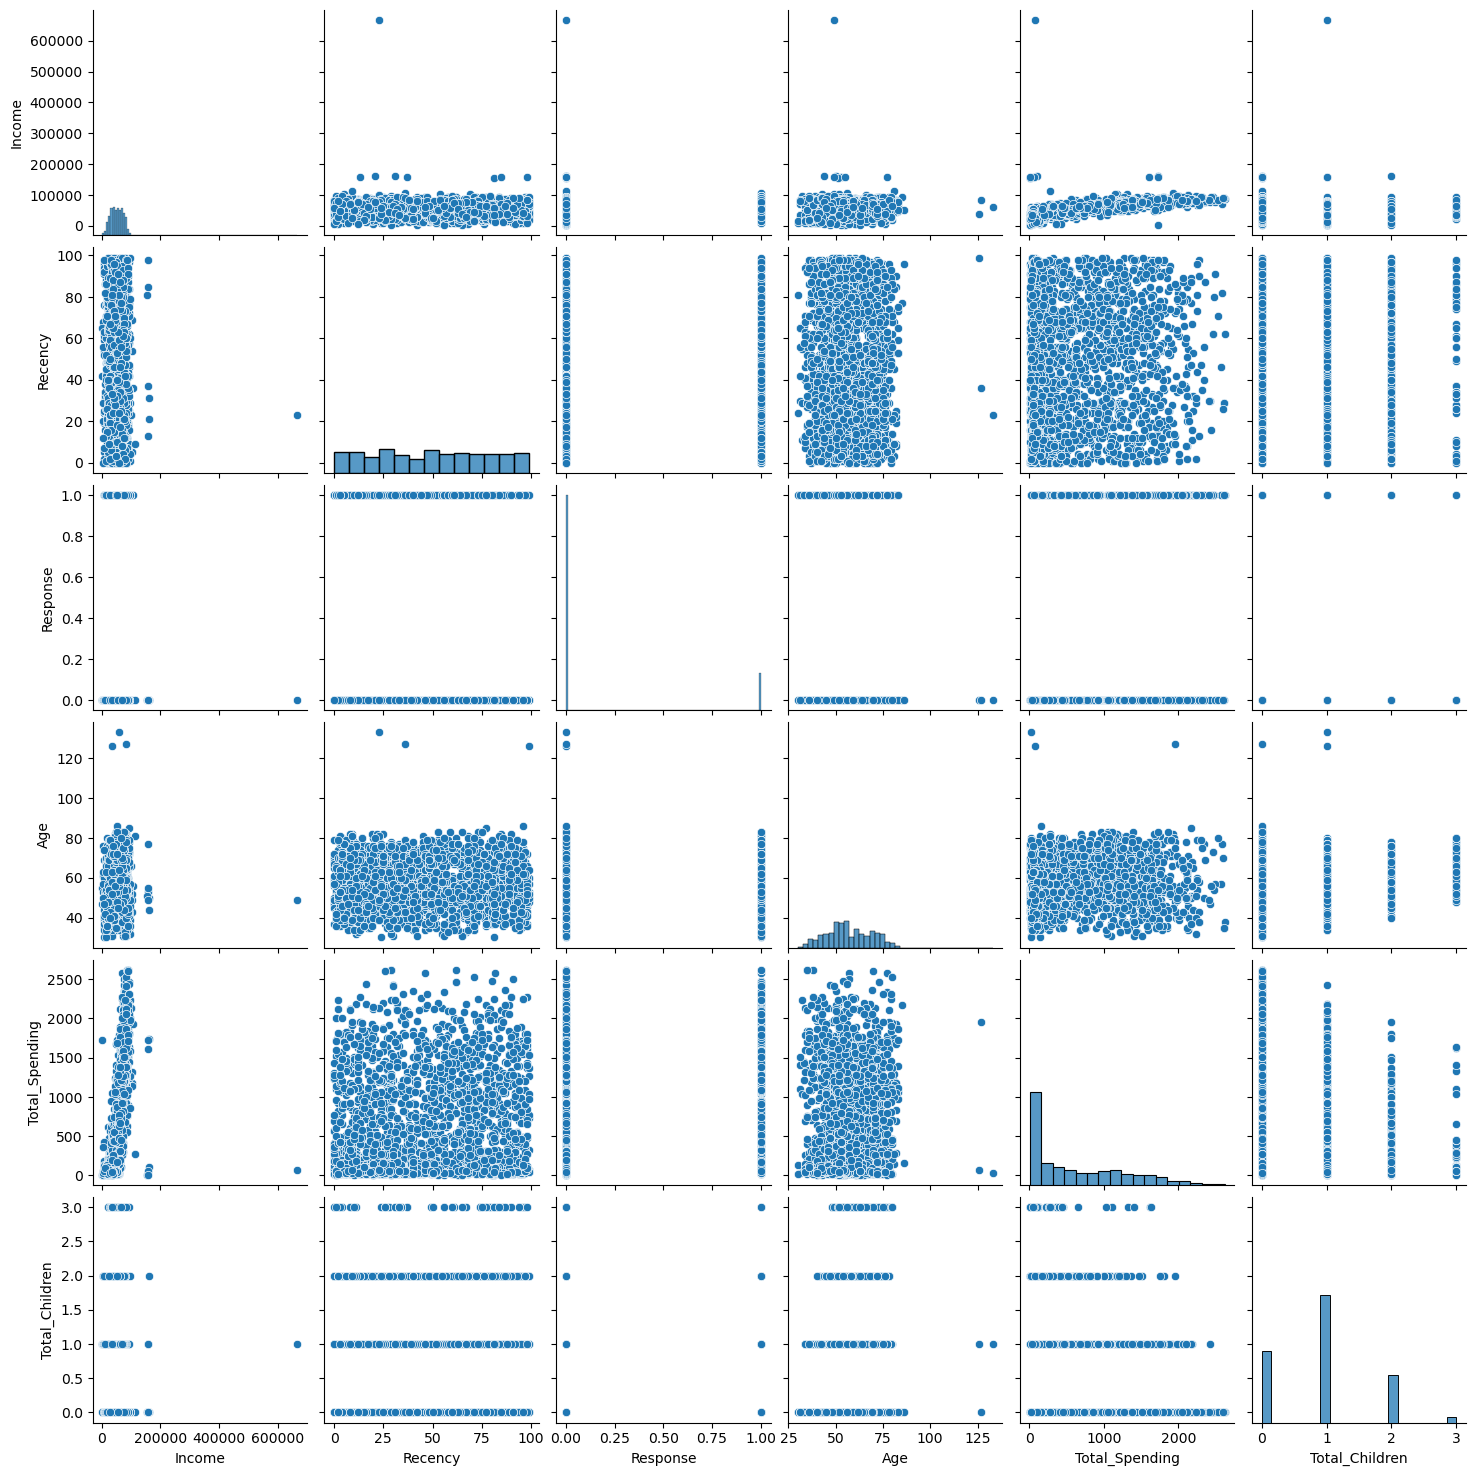

In [33]:
# Detecting Outliers
cols = ["Income", "Recency", "Response", "Age", "Total_Spending", "Total_Children"]

# Relative plots of some features - pair plots
sns.pairplot(df_cleaned[cols])

In [35]:
# Removing Outliers
print("Data size with outliers: ", len(df_cleaned))

df_cleaned = df_cleaned[(df_cleaned["Age"] < 90)]
df_cleaned = df_cleaned[(df_cleaned["Income"] < 600_000)]

print("Data size without outliers: ", len(df_cleaned))

Data size with outliers:  2240
Data size without outliers:  2236


## Heatmap

In [36]:
corr = df_cleaned.corr(numeric_only = True)

<Axes: >

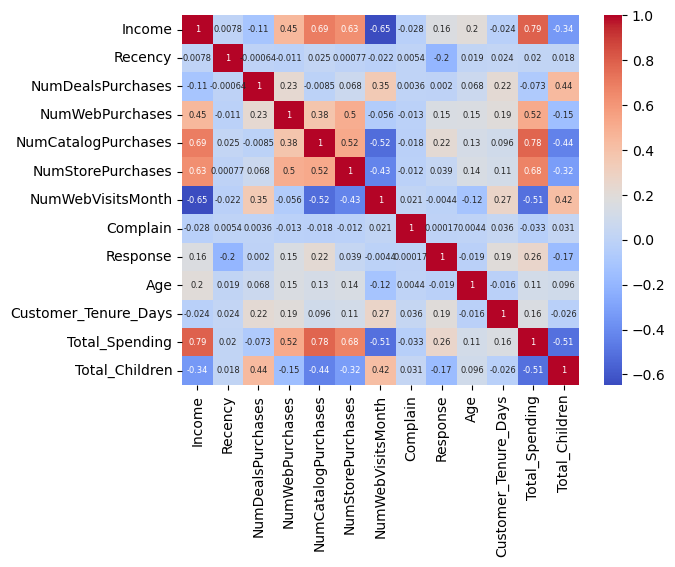

In [39]:
sns.heatmap(
    corr,
    annot = True,
    annot_kws = {"size" : 6},
    cmap = "coolwarm"
)

Some conclusive findings from heatmap -
##### Positive Correlation:
Income and Total_Spending
Income and NumCatalogPurchases
Income and NumStorePurchases
Total_Spending and NumCatalogPurchases
Total_Spending and NumStorePurchases

##### Negative Correlation:
Income and NumWebVisitsMonths
NumWebVisitsMonths and NumCatalogPurchases

In [40]:
df_cleaned.shape

(2236, 15)

In [41]:
df_cleaned.head()

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Living_With
0,Graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1789,0,Alone
1,Graduate,46344.0,38,2,1,1,2,5,0,0,72,113,29,2,Alone
2,Graduate,71613.0,26,1,8,2,10,4,0,0,61,312,887,0,Partner
3,Graduate,26646.0,26,2,2,0,4,6,0,0,42,139,63,1,Partner
4,Postgraduate,58293.0,94,5,5,3,6,5,0,0,45,161,468,1,Partner


# Feature Encoding

In [42]:
from sklearn.preprocessing import OneHotEncoder

In [46]:
ohe = OneHotEncoder()

cat_cols = ["Education", "Living_With"]
enc_cols = ohe.fit_transform(df_cleaned[cat_cols])

In [47]:
enc_df = pd.DataFrame(enc_cols.toarray(), columns = ohe.get_feature_names_out(cat_cols), index = df_cleaned.index)

In [48]:
enc_df.head()

,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Living_With_Alone,Living_With_Partner
0,1.0,0.0,0.0,1.0,0.0
1,1.0,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,0.0,1.0
3,1.0,0.0,0.0,0.0,1.0
4,0.0,1.0,0.0,0.0,1.0


In [49]:
df_encoded = pd.concat([df_cleaned.drop(columns = cat_cols), enc_df], axis = 1)

In [50]:
df_encoded.shape

(2236, 18)

In [52]:
df_encoded.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Living_With_Alone,Living_With_Partner
0,58138.0,58,3,8,10,4,7,0,1,69,663,1789,0,1.0,0.0,0.0,1.0,0.0
1,46344.0,38,2,1,1,2,5,0,0,72,113,29,2,1.0,0.0,0.0,1.0,0.0
2,71613.0,26,1,8,2,10,4,0,0,61,312,887,0,1.0,0.0,0.0,0.0,1.0
3,26646.0,26,2,2,0,4,6,0,0,42,139,63,1,1.0,0.0,0.0,0.0,1.0
4,58293.0,94,5,5,3,6,5,0,0,45,161,468,1,0.0,1.0,0.0,0.0,1.0


# Scaling

In [53]:
from sklearn.preprocessing import StandardScaler

In [55]:
X = df_encoded

In [56]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Visualize

In [57]:
X_scaled.shape

(2236, 18)

In [59]:
from sklearn.decomposition import PCA

In [60]:
# 2D
pca = PCA(
    n_components = 2
)

X_pca = pca.fit_transform(X_scaled)

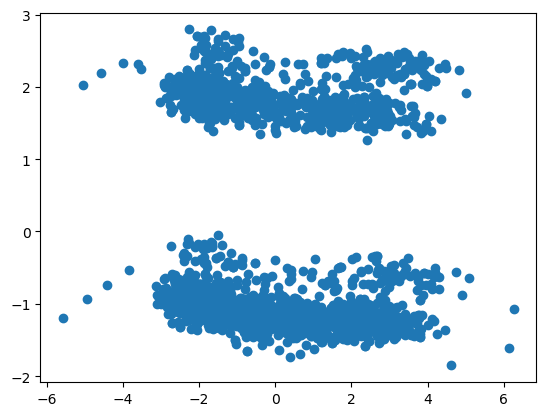

In [62]:
# plot
plt.scatter(x = X_pca[:, 0], y = X_pca[:, 1])

In [64]:
pca.explained_variance_ratio_

array([0.23177386, 0.11385357])

In 2D it is not able to capture much variance so we will try increasing the dimensions

In [65]:
# 3D
pca = PCA(
    n_components = 3
)

X_pca = pca.fit_transform(X_scaled)

In [66]:
pca.explained_variance_ratio_

array([0.23177386, 0.11385357, 0.10403506])

Text(0.5, 0.92, '3D projection')

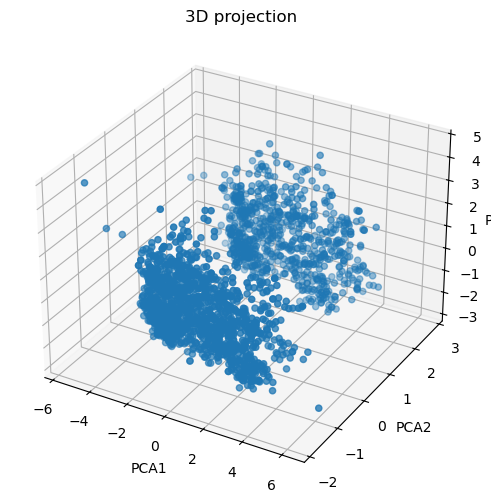

In [75]:
fig = plt.figure(figsize = (8, 6))
ax = fig.add_subplot(111, projection = "3d")
ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2])
ax.set_xlabel("PCA1")
ax.set_ylabel("PCA2")
ax.set_zlabel("PCA3")
ax.set_title("3D projection")

# KMeans

In [76]:
# Analyze K value:

In [78]:
# Elbow method 

from sklearn.cluster import KMeans
from kneed import KneeLocator
import warnings

warnings.filterwarnings(
    "ignore",
    message="KMeans is known to have a memory leak on Windows with MKL.*",
    category=UserWarning
)

wcss = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters = k, random_state = 42)
    kmeans.fit_predict(X_pca)
    wcss.append(kmeans.inertia_)

In [81]:
knee = KneeLocator(range(1, 11), wcss, curve = "convex", direction = "decreasing")
optimal_k = knee.elbow

In [83]:
print("Best k: ", optimal_k)

Best k:  4


Text(0, 0.5, 'WCSS')

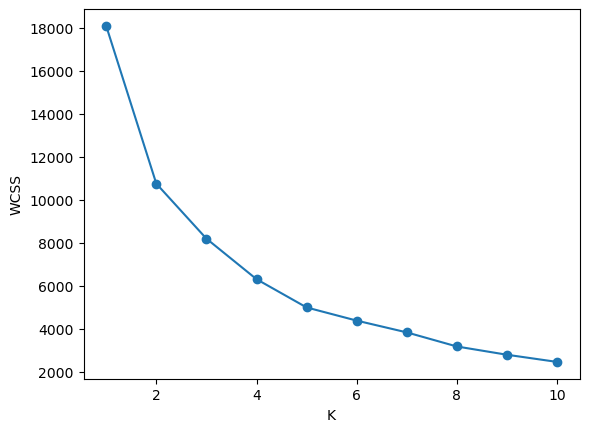

In [86]:
# plot
plt.plot(range(1, 11), wcss, marker = "o")
plt.xlabel("K")
plt.ylabel("WCSS")

In [87]:
# Silhouette score

from sklearn.metrics import silhouette_score

scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters = k, random_state = 42)
    labels = kmeans.fit_predict(X_pca)
    score = silhouette_score(X_pca, labels)
    scores.append(score)

Text(0, 0.5, 'Silhouette score')

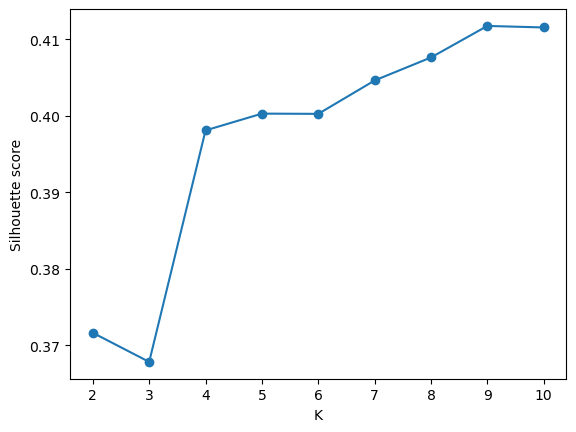

In [90]:
# plot
plt.plot(range(2, 11), scores, marker = "o")
plt.xlabel("K")
plt.ylabel("Silhouette score")

Text(0, 0.5, 'Silhouette score')

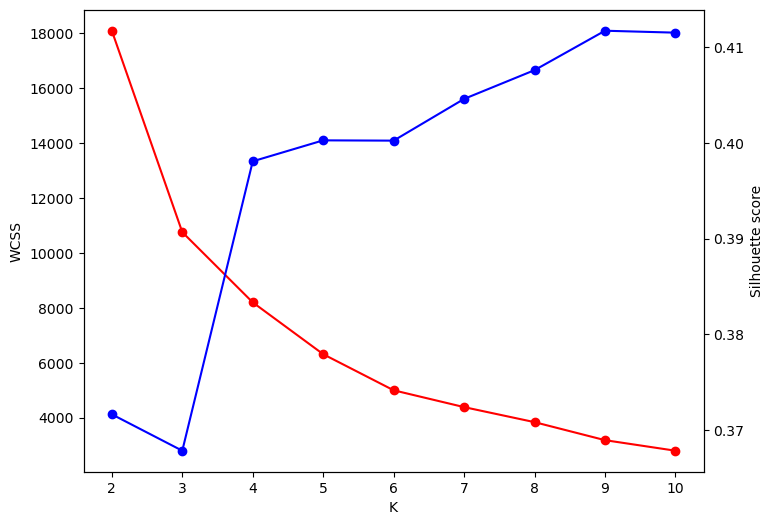

In [99]:
# Combined plot for wcss and silhouette score
k_range = range(2, 11)
fig, ax1 = plt.subplots(figsize = (8, 6))
ax1.plot(k_range, wcss[:len(k_range)], marker = "o", color = "red")
ax1.set_xlabel("K")
ax1.set_ylabel("WCSS")

ax2 = ax1.twinx()
ax2.plot(k_range, scores[:len(k_range)], marker = "o", color = "blue")
ax2.set_ylabel("Silhouette score")

Since both graphs are intersecting around 4, the optimal value for k is 4 

# KMeans Clustering

Text(0.5, 0.92, '3D projection')

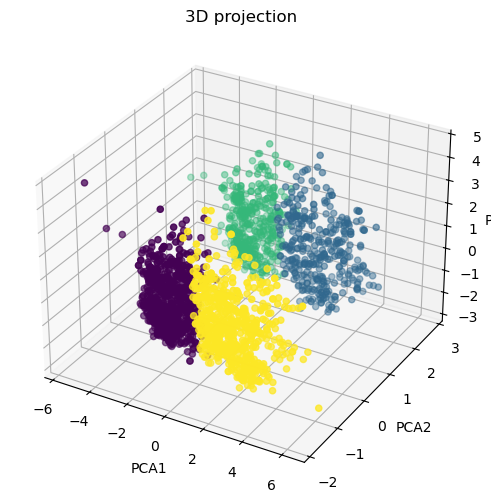

In [101]:
kmeans = KMeans(n_clusters = 4, random_state = 42)
labels_kmeans = kmeans.fit_predict(X_pca)

fig = plt.figure(figsize = (8, 6))
ax = fig.add_subplot(111, projection = "3d")
ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], c = labels_kmeans)
ax.set_xlabel("PCA1")
ax.set_ylabel("PCA2")
ax.set_zlabel("PCA3")
ax.set_title("3D projection")

# Agglomerative Hierarchial Clustering

In [102]:
from sklearn.cluster import AgglomerativeClustering

Text(0.5, 0.92, '3D projection')

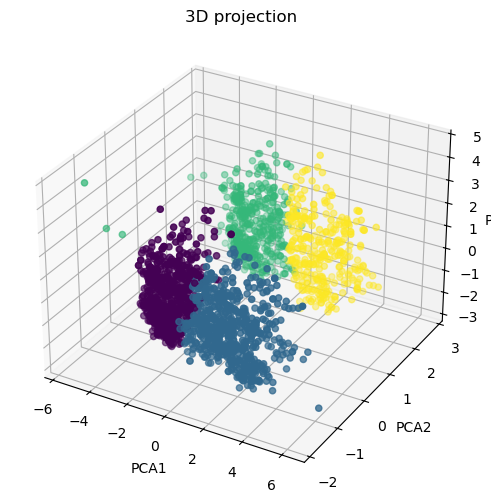

In [103]:
agg = AgglomerativeClustering(
    n_clusters = 4,
    linkage = "ward"
)

labels_agg = agg.fit_predict(X_pca)

fig = plt.figure(figsize = (8, 6))
ax = fig.add_subplot(111, projection = "3d")
ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], c = labels_agg)
ax.set_xlabel("PCA1")
ax.set_ylabel("PCA2")
ax.set_zlabel("PCA3")
ax.set_title("3D projection")

# Characterization of clusters

In [114]:
X["clusters"] = labels_agg

In [115]:
X.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Living_With_Alone,Living_With_Partner,clusters
0,58138.0,58,3,8,10,4,7,0,1,69,663,1789,0,1.0,0.0,0.0,1.0,0.0,3
1,46344.0,38,2,1,1,2,5,0,0,72,113,29,2,1.0,0.0,0.0,1.0,0.0,2
2,71613.0,26,1,8,2,10,4,0,0,61,312,887,0,1.0,0.0,0.0,0.0,1.0,1
3,26646.0,26,2,2,0,4,6,0,0,42,139,63,1,1.0,0.0,0.0,0.0,1.0,0
4,58293.0,94,5,5,3,6,5,0,0,45,161,468,1,0.0,1.0,0.0,0.0,1.0,0


<Axes: xlabel='clusters', ylabel='count'>

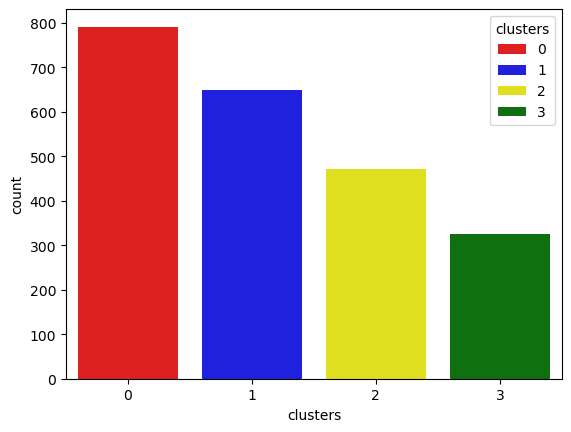

In [116]:
# Number of customers in each cluster

pal = ["red", "blue", "yellow", "green"]
sns.countplot(x = X["clusters"], palette = pal, hue = X["clusters"])

<Axes: xlabel='Total_Spending', ylabel='Income'>

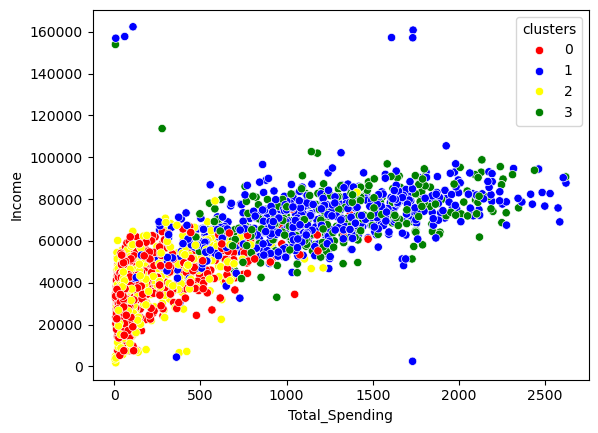

In [117]:
# Income and spending patterns

sns.scatterplot(x = X["Total_Spending"], y = X["Income"], hue = X["clusters"], palette = pal)

In [122]:
# Cluster Summary

cluster_summary = X.groupby("clusters").mean()
print(cluster_summary)

                Income    Recency  NumDealsPurchases  NumWebPurchases  \
clusters                                                                
0         37289.371681  48.747155           2.677623         2.881163   
1         69899.293210  49.356481           1.969136         5.574074   
2         38182.978814  48.466102           2.595339         2.917373   
3         71855.520000  50.480000           1.790769         5.760000   

          NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth  Complain  \
clusters                                                                        
0                    0.804046           3.780025           6.585335  0.008850   
1                    4.902778           8.308642           3.720679  0.009259   
2                    0.942797           3.836864           6.578390  0.010593   
3                    5.221538           8.535385           3.593846  0.006154   

          Response        Age  Customer_Tenure_Days  Total_Spending  \
clu

## Basic Insights 

Cluster 0 are the "Family Shoppers", they have partners and more children, income is low to moderate and thus spending is low to moderate, poor response, more website visits but less purchases from all - websites, stores and catalog. They can be offered discounts and coupons to increase their engagement with the brands

Cluster 1 are the ones with partners and fewer children, high income and high spendings, average response, website visits are less but purchases from all - websites, stores and catalog are high. They can be offered loyalty programs 

Cluster 2 are the "Digital Browsers", they alone with more children, income and spendings are low to moderate, average response, website visists are high but purchases are low. They can be offered sales with heavy discounts and coupon amounts 

Cluster 3 are alone, with fewer children, higher income and higher spendings, best response, web visits are less but purchase are high from all - web, store and catalog. This cluster has the best ROI in terms of sending, income as well as response. These are the "High Value Singles". They can be offered premium services